<a href="https://colab.research.google.com/github/drdave-teaching/OPIM3510-BDA1/blob/main/M1_Python_Bootcamp/Week03_EDA/1_EDA_CT_Home_Sales_answers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA Walkthrough: Connecticut Home Sales (answers)
**OPIM 3510 Python Bootcamp · Dr. Dave Wanik · University of Connecticut**

-------------------------------
Exploratory Data Analysis (EDA) is all about **getting to know your data and telling a story with it**.

We'll use **real Connecticut home sales**: about 27,000 homes sold between October 2024 and September 2025, with the sale price, the town's assessed value, and each house's features (bedrooms, baths, square feet, year built, heating fuel and more).

*Data: Connecticut OPM Real Estate Sales and the 2025 Connecticut Parcel and CAMA Data (data.ct.gov), matched by town and address. Addresses and owner names were removed, and map coordinates are rounded to about one block.*

Each numbered section is short and stands on its own. Type the code yourself - don't just copy/paste - so it gets into your fingers.

## 1. Set up and read the data
Import your modules (keep them at the top of your notebook), then read the data with `pandas`.

In [1]:
# import modules
import pandas as pd # for data wrangling and tables
import numpy as np # for numeric python
import matplotlib.pyplot as plt # for plots
import seaborn as sns # for nicer plots

# read the data straight from the course GitHub repo
DATA_URL = "https://raw.githubusercontent.com/drdave-teaching/OPIM3510-BDA1/main/data/ct_home_sales_2025.csv"
df = pd.read_csv(DATA_URL)

In [2]:
# look at the first few rows
df.head()

,town,date_recorded,residential_type,sale_price,assessed_value,living_area_sqft,bedrooms,full_baths,half_baths,total_rooms,year_built,stories,lot_acres,style,condition,heat_fuel,air_conditioning,fireplaces,longitude,latitude
0,Marlborough,0024-10-15,Single Family,256500.0,334650,3332.0,4.0,2.0,1.0,10.0,1740.0,2.00,4.25,Old Style,Good,Oil,NaN,4.0,-72.433,41.608
1,Marlborough,0024-10-24,Single Family,775000.0,427990,2746.0,4.0,3.0,0.0,9.0,1749.0,2.00,0.40,Old Style,Excellent,Propane Gas,Central,3.0,-72.471,41.637
2,Marlborough,0024-10-30,Single Family,370000.0,174620,1467.0,3.0,3.0,0.0,6.0,1965.0,1.00,1.78,Ranch,Average,Oil,Central,1.0,-72.468,41.679
3,Marlborough,0024-10-31,Single Family,186000.0,153210,1545.0,3.0,1.0,0.0,5.0,1938.0,1.75,0.87,Cape,Good,Oil,NaN,0.0,-72.466,41.675
4,Marlborough,0024-10-31,Single Family,375000.0,240170,2273.0,3.0,2.0,1.0,6.0,1985.0,2.00,5.36,Colonial,Good,Oil,NaN,2.0,-72.438,41.612


Each row is **one home sale** recorded in Connecticut between October 2024 and September 2025, with the sale price, the town's assessed value, and the house's features from the town assessor's records. `sale_price` is our **target**: the number we want to understand.

## 2. Shape, columns, data types and missing values
What are you working with? How many rows and columns? Any wrong data types? Any missing values? **Always check this first.**

In [3]:
# shape of the data (ROWS, COLUMNS) - an attribute, so no round brackets
df.shape

(27313, 20)

In [4]:
# column names
df.columns

Index(['town', 'date_recorded', 'residential_type', 'sale_price',
       'assessed_value', 'living_area_sqft', 'bedrooms', 'full_baths',
       'half_baths', 'total_rooms', 'year_built', 'stories', 'lot_acres',
       'style', 'condition', 'heat_fuel', 'air_conditioning', 'fireplaces',
       'longitude', 'latitude'],
      dtype='object')

In [5]:
# missing values per column
df.isna().sum()

town                    0
date_recorded           0
residential_type        0
sale_price              0
assessed_value          0
living_area_sqft        0
bedrooms                0
full_baths              0
half_baths            322
total_rooms           232
year_built              1
stories                60
lot_acres              14
style                   0
condition             218
heat_fuel             614
air_conditioning    14412
fireplaces          13408
longitude              79
latitude               79
dtype: int64

In [6]:
# data types, non-missing counts and memory, all in one line
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27313 entries, 0 to 27312
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   town              27313 non-null  object 
 1   date_recorded     27313 non-null  object 
 2   residential_type  27313 non-null  object 
 3   sale_price        27313 non-null  float64
 4   assessed_value    27313 non-null  int64  
 5   living_area_sqft  27313 non-null  float64
 6   bedrooms          27313 non-null  float64
 7   full_baths        27313 non-null  float64
 8   half_baths        26991 non-null  float64
 9   total_rooms       27081 non-null  float64
 10  year_built        27312 non-null  float64
 11  stories           27253 non-null  float64
 12  lot_acres         27299 non-null  float64
 13  style             27313 non-null  object 
 14  condition         27095 non-null  object 
 15  heat_fuel         26699 non-null  object 
 16  air_conditioning  12901 non-null  object

What jumps out:
* `date_recorded` is stored as **text**, not a date. We'll fix that.
* `air_conditioning` is missing for about **half** the sales, and so is `fireplaces`. Missing doesn't always mean "no" - some towns just don't record it.
* `town`, `residential_type`, `style`, `condition` and `heat_fuel` are **categories** (text).

## 3. Summary statistics
Measures of **center** (mean, median, mode) and **spread** (standard deviation, percentiles).

In [7]:
# describe() summarizes every numeric column at once
df.describe().round(1)

,sale_price,assessed_value,living_area_sqft,bedrooms,full_baths,half_baths,total_rooms,year_built,stories,lot_acres,fireplaces,longitude,latitude
count,27313.0,27313.0,27313.0,27313.0,27313.0,26991.0,27081.0,27312.0,27253.0,27299.0,13905.0,27234.0,27234.0
mean,601256.5,294431.2,1913.6,3.3,1.9,0.5,7.0,1957.7,1.7,0.8,49.8,-72.9,41.5
std,752804.2,375187.9,1065.0,1.2,0.9,0.6,2.7,41.5,1.3,2.1,287.4,0.4,0.3
min,5000.0,4700.0,280.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-73.7,41.0
25%,309000.0,144550.0,1212.0,3.0,1.0,0.0,5.0,1941.0,1.0,0.1,0.0,-73.2,41.3
50%,415000.0,200480.0,1608.0,3.0,2.0,0.0,7.0,1963.0,1.8,0.3,1.0,-72.9,41.5
75%,620000.0,309960.0,2324.0,4.0,2.0,1.0,8.0,1985.0,2.0,0.9,1.0,-72.6,41.7
max,21000000.0,10472420.0,16216.0,20.0,14.0,5.0,89.0,2025.0,24.0,139.7,5485.0,-71.8,42.0


In [8]:
# measures of center for the target
print('mean:  ', round(df['sale_price'].mean()))
print('median:', df['sale_price'].median())
print('mode:  ', df['sale_price'].mode()[0])

mean:   601256
median: 415000.0
mode:   350000.0


The **mean (about \$601K) is much bigger than the median (\$415K)**. That's the signature of a **right-skewed** distribution: a handful of multi-million-dollar sales drag the average up. For skewed data like home prices, the median is the better "typical" value - that's why real estate reports always quote the *median* sale price.

In [9]:
# percentiles: 10% of sales are at or below the first number, and so on
df['sale_price'].quantile([0.1, 0.25, 0.5, 0.75, 0.9])

0.10     230000.0
0.25     309000.0
0.50     415000.0
0.75     620000.0
0.90    1000000.0
Name: sale_price, dtype: float64

The top 10% of sales are **\$1 million or more**, and the bottom 10% are under about \$230K. Percentiles tell this story much better than a mean and standard deviation.

## 4. Clean up dates and impossible values
Before trusting any column, ask: **is this value even possible?**

In [10]:
# how many dates have a strange year? (look at the first 4 characters)
df['date_recorded'].str.slice(0, 4).value_counts()

date_recorded
2025    19805
2024     7424
0025       66
0024       18
Name: count, dtype: int64

84 sales were recorded in the year **0024** or **0025** - typos for 2024 and 2025. (Did you spot them in the very first rows of `df.head()`? Sorting puts them first!) Fix the text first, *then* convert it to a real date:

In [11]:
# fix the typos
df['date_recorded'] = df['date_recorded'].str.replace('0024-', '2024-')
df['date_recorded'] = df['date_recorded'].str.replace('0025-', '2025-')

# now convert to a real datetime
df['date_recorded'] = pd.to_datetime(df['date_recorded'])

# check your work
df['date_recorded'].min(), df['date_recorded'].max()

(Timestamp('2024-10-01 00:00:00'), Timestamp('2025-09-30 00:00:00'))

In [12]:
# impossible values hiding in numeric columns
print('houses built in year 0:     ', (df['year_built'] == 0).sum())
print('houses with 10+ fireplaces: ', (df['fireplaces'] > 10).sum())
print('largest fireplace count:    ', df['fireplaces'].max())

houses built in year 0:      1
houses with 10+ fireplaces:  1090
largest fireplace count:     5485.0


A house built in the year 0, and **over a thousand homes with "fireplaces" in the thousands**? Those are data-entry and software glitches, not real fireplaces. Recode impossible values as missing (`NaN`) so they don't poison your averages:

In [13]:
# recode impossible values as missing
df.loc[df['year_built'] == 0, 'year_built'] = np.nan
df.loc[df['fireplaces'] > 10, 'fireplaces'] = np.nan

# check your work
df[['year_built', 'fireplaces']].describe().round(1)

,year_built,fireplaces
count,27311.0,12815.0
mean,1957.8,0.8
std,39.8,1.1
min,1647.0,0.0
25%,1941.0,0.0
50%,1963.0,1.0
75%,1985.0,1.0
max,2025.0,10.0


## 5. Flag variables and subsetting
A **flag** is a 0/1 column made from a condition - just like `=IF()` in Excel. Flags make it easy to split the data into groups.

In [14]:
# flag the million-dollar sales
df['FLAG_million'] = np.where(df['sale_price'] >= 1000000, 1, 0)

# how many in each group?
df['FLAG_million'].value_counts()

FLAG_million
0    24536
1     2777
Name: count, dtype: int64

In [15]:
# subset just the single-family homes
single = df[df['residential_type'] == 'Single Family']
print(single.shape)

(20548, 21)


In [16]:
# subset sales in one town (try your own town!)
madison = df[df['town'] == 'Madison']
print(madison.shape)
print('Madison median sale price:', madison['sale_price'].median())

(216, 21)
Madison median sale price: 707500.0


## 6. Group by (pivot tables)
`groupby` calculates statistics **per group** - the pandas version of a pivot table.

In [17]:
# median price and number of sales for each type of home
df.groupby('residential_type')['sale_price'].agg(['median', 'count'])

,median,count
residential_type,,
Condo,290000.0,4166
Four Family,479500.0,150
Single Family,449000.0,20548
Three Family,425000.0,809
Two Family,380000.0,1640


In [18]:
# the 10 most expensive towns (only towns with at least 20 sales, so a few big sales can't fool us)
by_town = df.groupby('town')['sale_price'].agg(['median', 'count'])
by_town = by_town[by_town['count'] >= 20]
by_town.sort_values('median', ascending=False).head(10)

,median,count
town,,
Greenwich,2300000.0,574
New Canaan,2287500.0,208
Westport,1976250.0,338
Wilton,1302500.0,220
Weston,1297000.0,120
Roxbury,1275000.0,33
Ridgefield,1006500.0,179
Fairfield,925000.0,521
Easton,907500.0,88


Greenwich, New Canaan and Westport top the list - Fairfield County's "Gold Coast". Change `ascending=False` to `True` to see the most affordable towns.

In [19]:
# single-family homes: median price by number of bedrooms
single.groupby('bedrooms')['sale_price'].agg(['median', 'count']).head(7)

,median,count
bedrooms,,
1.0,300000.0,199
2.0,318000.0,2749
3.0,410000.0,10612
4.0,625000.0,5457
5.0,1050000.0,1175
6.0,2000000.0,265
7.0,2062500.0,70


In [20]:
# which months are busiest? (dates unlock new groupings)
df.groupby(df['date_recorded'].dt.month)['sale_price'].count()

date_recorded
1     1795
2     1451
3     1793
4     1989
5     2199
6     2707
7     2854
8     2682
9     2401
10    2555
11    2384
12    2503
Name: sale_price, dtype: int64

Sales peak in **June and July**. Families like to move between school years.

## 7. Univariate plots (one variable at a time)
Histograms, boxplots and density plots show the **shape** of a distribution. Bar plots are for **categories**. Every plot needs a title and axis labels - no excuses!

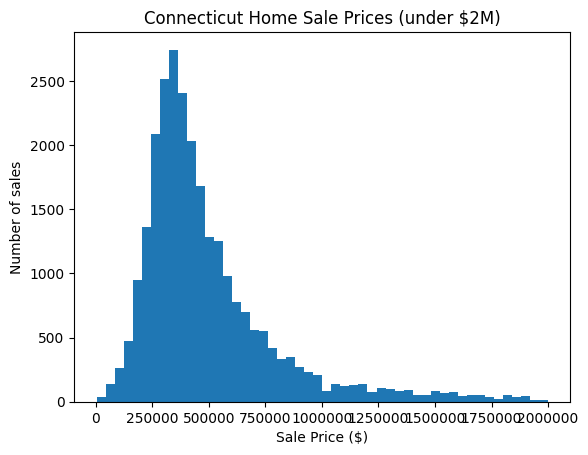

In [21]:
# histogram of sale price (sales under $2M, so we can see the bulk of the market)
under_2m = df[df['sale_price'] < 2000000]

plt.hist(under_2m['sale_price'], bins=50)
plt.xlabel('Sale Price ($)')
plt.ticklabel_format(style='plain', axis='x') # show 500000, not 0.5 x 1e6
plt.ylabel('Number of sales')
plt.title('Connecticut Home Sale Prices (under $2M)')
plt.show()

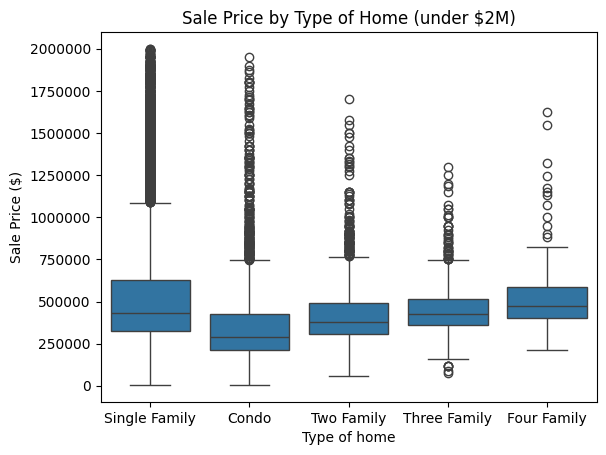

In [22]:
# boxplot of price for each type of home
sns.boxplot(data=under_2m, x='residential_type', y='sale_price')
plt.xlabel('Type of home')
plt.ylabel('Sale Price ($)')
plt.ticklabel_format(style='plain', axis='y') # show 500000, not 0.5 x 1e6
plt.title('Sale Price by Type of Home (under $2M)')
plt.show()

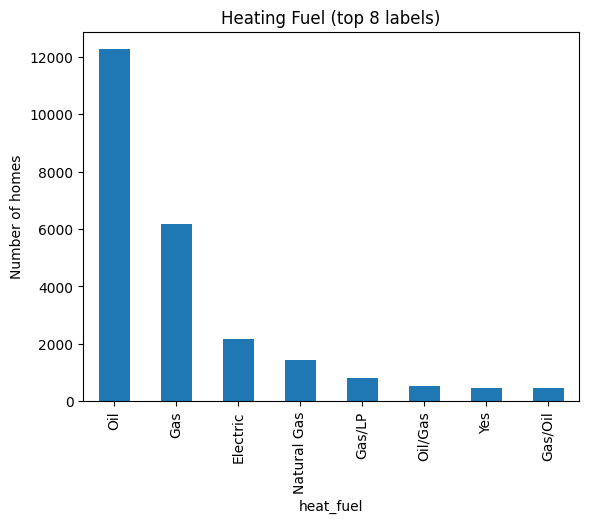

In [23]:
# bar plot for a category: how are Connecticut homes heated?
df['heat_fuel'].value_counts().head(8).plot.bar()
plt.ylabel('Number of homes')
plt.title('Heating Fuel (top 8 labels)')
plt.show()

**Oil** heats nearly half of the homes in this data - very Connecticut! But look closely at the labels: `Gas` and `Natural Gas` are probably the same thing, entered differently by different towns' software. Messy categories like this are everywhere in real data (more on cleaning them in Module 3).

## 8. Bivariate plots and correlation (two variables at a time)
Scatterplots show how two numeric variables move together. **Correlation** puts a number on it: +1 is a perfect increasing line, 0 is no linear relationship, -1 is a perfect decreasing line.

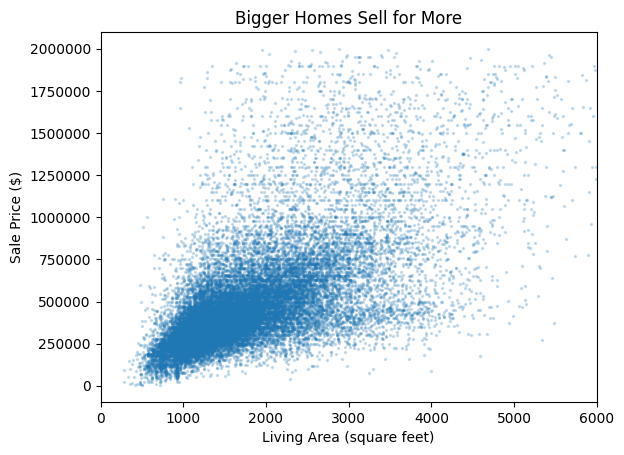

In [24]:
# scatterplot: size of the house vs. price
plt.scatter(x=under_2m['living_area_sqft'], y=under_2m['sale_price'], s=2, alpha=0.2)
plt.xlim(0, 6000)
plt.xlabel('Living Area (square feet)')
plt.ylabel('Sale Price ($)')
plt.ticklabel_format(style='plain', axis='y') # show 500000, not 0.5 x 1e6
plt.title('Bigger Homes Sell for More')
plt.show()

In [25]:
# correlation of every numeric column with sale price (leave out our 0/1 flag)
corr = df.drop(columns=['FLAG_million']).corr(numeric_only=True)
corr['sale_price'].sort_values()

latitude           -0.357686
longitude          -0.336125
stories             0.065865
year_built          0.090205
lot_acres           0.169971
fireplaces          0.278375
bedrooms            0.304104
half_baths          0.333758
total_rooms         0.393684
full_baths          0.591754
living_area_sqft    0.679977
assessed_value      0.960464
sale_price          1.000000
Name: sale_price, dtype: float64

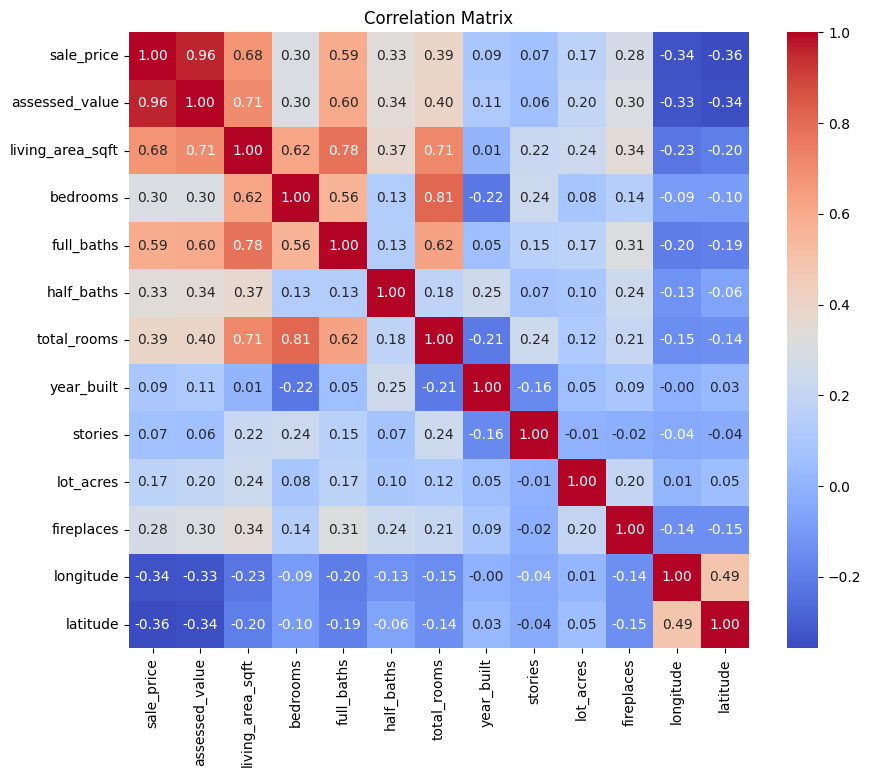

In [26]:
# correlation heatmap with the numbers printed on it
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

`assessed_value` is almost perfectly correlated with price (about 0.96) - that's the town's own estimate of the home's value. Among the house features, **living area** (about 0.68) and **full baths** (about 0.59) matter most. Bedrooms matter less than you might think (about 0.30) once you know how big the house is.

## 9. Make a map!
Latitude and longitude are just numbers - plot them and you get a map of Connecticut. Color by price to see the story.

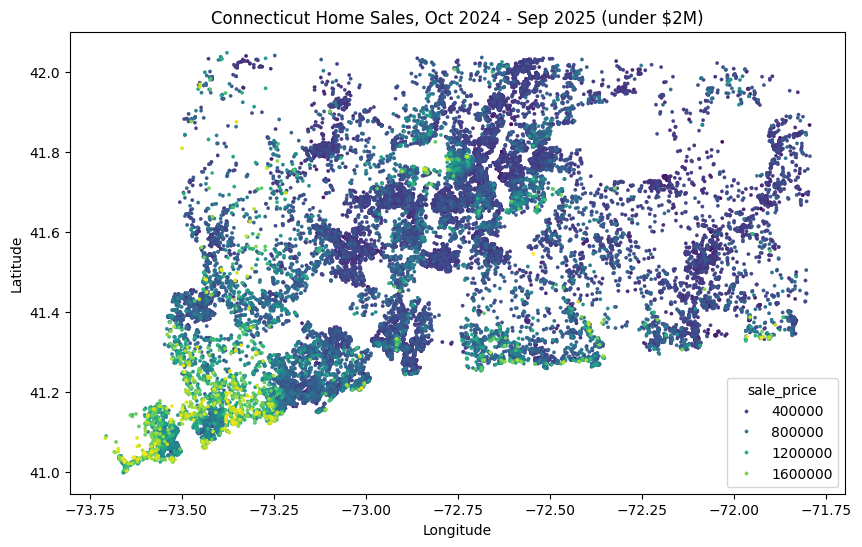

In [27]:
# sort so the most expensive sales are drawn last (on top)
map_data = under_2m.sort_values('sale_price')

plt.figure(figsize=(10, 6))
sns.scatterplot(data=map_data, x='longitude', y='latitude', hue='sale_price', palette='viridis', s=6, edgecolor=None)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Connecticut Home Sales, Oct 2024 - Sep 2025 (under $2M)')
plt.show()

The expensive sales hug the **southwest corner** (Fairfield County, close to New York City) and the **shoreline**. You can also make out the cities - Hartford, New Haven, Waterbury - as dense clusters of less expensive sales.

## 10. Your turn
1. **Your town.** Subset the sales for your town (or a town you know). What's the median price? How does it compare to the state?
2. **Oil vs. gas.** Do homes heated with oil sell for more or less than homes heated with gas? (Careful: combine `Gas` and `Natural Gas` first!)
3. **Old homes.** Make a flag for homes built before 1940. Are they bigger or smaller than newer homes?
4. **The real challenge:** open a brand-new dataset and run this whole template in 15 minutes. It's not about memorizing - it's about the code flowing out of your fingers.